# Study-time model comparison

Reads the artifacts written by `python ml/src/train.py`.

## 1. Load data and split

In [1]:
import json
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Notebook runs from ml/notebooks; make the ml package importable
ROOT = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(ROOT))

from ml.src.features import TARGET
from ml.src.train import META_PATH, MODEL_PATH, RESULTS_PATH, SEED, build_models, load_data, split_by_student

TYPE_ORDER = ["Reading", "Homework", "Lab", "Exam", "Project"]

# Chart styling, same as 01_eda.ipynb
BLUE = "#2a78d6"
INK = "#52514e"
GRID = "#e1e0d9"
plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "xtick.color": INK,
    "ytick.color": INK,
})

train, test = split_by_student(load_data(), SEED)
shared = set(train["student_id"]) & set(test["student_id"])
print(f"Train: {len(train)} rows, {train['student_id'].nunique()} students")
print(f"Test: {len(test)} rows, {test['student_id'].nunique()} students")
print(f"Students in both: {len(shared)}")

Train: 1116 rows, 40 students
Test: 257 rows, 10 students
Students in both: 0


## 2. Cross-validation results table

In [2]:
# 5-fold GroupKFold on the train set, best CV MAE first
results = pd.read_csv(RESULTS_PATH)
cv_columns = ["model", "include_days", "cv_mae_mean", "cv_mae_std", "cv_rmse_mean",
              "cv_rmse_std", "cv_r2_mean", "cv_r2_std", "selected"]
results.sort_values("cv_mae_mean")[cv_columns].round(3).reset_index(drop=True)

,model,include_days,cv_mae_mean,cv_mae_std,cv_rmse_mean,cv_rmse_std,cv_r2_mean,cv_r2_std,selected
0,log_linear,False,1.397,0.149,2.488,0.381,0.846,0.016,True
1,log_linear,True,1.403,0.133,2.487,0.339,0.845,0.013,False
2,random_forest,False,1.484,0.090,2.591,0.315,0.831,0.018,False
3,hist_gradient_boosting,False,1.489,0.133,2.614,0.405,0.830,0.015,False
4,hist_gradient_boosting,True,1.599,0.079,2.833,0.362,0.799,0.019,False
5,random_forest,True,1.617,0.073,2.741,0.178,0.808,0.022,False
6,linear,False,1.836,0.064,3.156,0.467,0.752,0.014,False
7,linear,True,1.848,0.058,3.179,0.442,0.748,0.012,False
8,baseline_type_mean,True,2.114,0.139,3.732,0.502,0.652,0.012,False
9,baseline_type_mean,False,2.114,0.139,3.732,0.502,0.652,0.012,False


## 3. Test set results

In [3]:
# Held-out students, never used for model selection
test_columns = ["model", "include_days", "test_mae", "test_rmse", "test_r2", "selected"]
results.sort_values("test_mae")[test_columns].round(3).reset_index(drop=True)

,model,include_days,test_mae,test_rmse,test_r2,selected
0,hist_gradient_boosting,False,1.657,2.992,0.842,False
1,log_linear,True,1.663,3.059,0.835,False
2,log_linear,False,1.668,3.041,0.837,True
3,hist_gradient_boosting,True,1.705,3.089,0.832,False
4,random_forest,False,1.753,3.498,0.784,False
5,random_forest,True,1.951,3.793,0.746,False
6,baseline_type_mean,True,2.142,4.043,0.712,False
7,baseline_type_mean,False,2.142,4.043,0.712,False
8,linear,True,2.196,3.666,0.763,False
9,linear,False,2.202,3.665,0.763,False


## 4. Predicted vs actual scatter for the best model

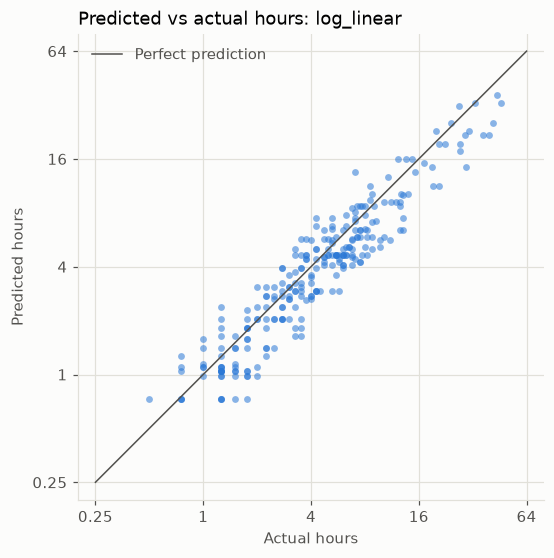

{'mae': 1.6679015297952573,
 'rmse': 3.0412953826171107,
 'r2': 0.8368548246336259}

In [4]:
model = joblib.load(MODEL_PATH)
meta = json.loads(META_PATH.read_text())
test = test.assign(predicted=model.predict(test[meta["features"]]))
test["abs_error"] = (test[TARGET] - test["predicted"]).abs()

# Log axes because hours span more than two orders of magnitude
ticks = [0.25, 1, 4, 16, 64]
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot([0.25, 64], [0.25, 64], color=INK, linewidth=1, label="Perfect prediction")
ax.scatter(test[TARGET], test["predicted"], s=20, color=BLUE, alpha=0.55, linewidths=0)
ax.set(xscale="log", yscale="log", xlim=(0.2, 80), ylim=(0.2, 80), aspect="equal")
ax.set_xticks(ticks, [str(t) for t in ticks])
ax.set_yticks(ticks, [str(t) for t in ticks])
ax.minorticks_off()
ax.set_title(f"Predicted vs actual hours: {meta['model_name']}", loc="left")
ax.set_xlabel("Actual hours")
ax.set_ylabel("Predicted hours")
ax.legend(frameon=False, labelcolor=INK, loc="upper left")
plt.show()

meta["test_metrics"]

## 5. Error by type (MAE per type)

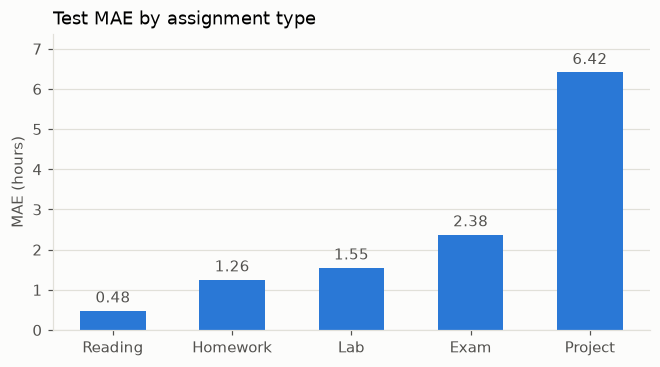

type
Reading     0.48
Homework    1.26
Lab         1.55
Exam        2.38
Project     6.42
Name: abs_error, dtype: float64

In [5]:
mae_by_type = test.groupby("type")["abs_error"].mean().reindex(TYPE_ORDER)

fig, ax = plt.subplots(figsize=(7, 3.5))
bars = ax.bar(mae_by_type.index, mae_by_type.values, width=0.55, color=BLUE)
ax.bar_label(bars, fmt="%.2f", padding=3, color=INK)
ax.set_title("Test MAE by assignment type", loc="left")
ax.set_ylabel("MAE (hours)")
ax.grid(axis="x", visible=False)
ax.margins(y=0.15)
plt.show()

mae_by_type.round(2)

## 6. Feature effect (linear-on-log coefficients as multipliers)

One-hot coefficients are only meaningful as differences within a feature, so each multiplier is relative to a reference level.

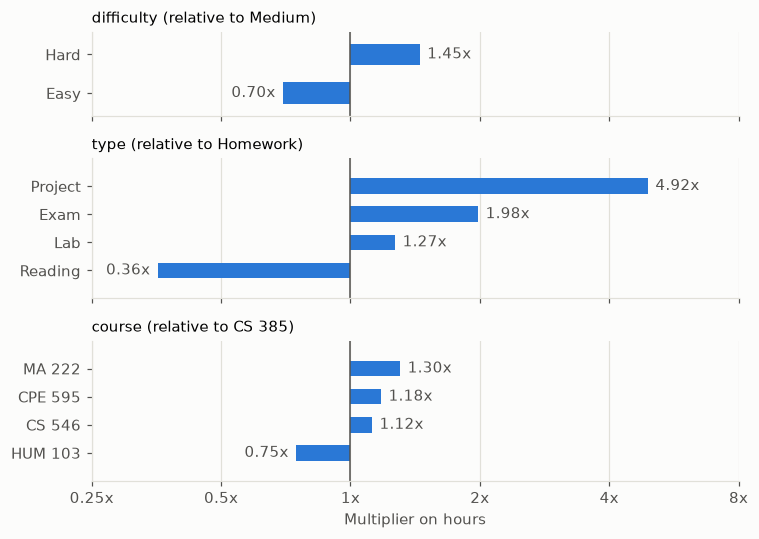

,feature,level,reference,multiplier
0,course,HUM 103,CS 385,0.75
1,course,CS 546,CS 385,1.12
2,course,CPE 595,CS 385,1.18
3,course,MA 222,CS 385,1.30
4,difficulty,Easy,Medium,0.70
5,difficulty,Hard,Medium,1.45
6,type,Reading,Homework,0.36
7,type,Lab,Homework,1.27
8,type,Exam,Homework,1.98
9,type,Project,Homework,4.92


In [6]:
REFERENCE = {"difficulty": "Medium", "type": "Homework", "course": "CS 385"}
columns = ["course", "type", "difficulty"]

# No-days fit, so type effects are not shared with lead time
log_linear = build_models(SEED, include_days=False)["log_linear"]
log_linear.fit(train[columns], train[TARGET])
names = log_linear["preprocess"].get_feature_names_out()
coefs = pd.Series(log_linear["model"].regressor_.coef_, index=names)

rows = []
for feature, reference in REFERENCE.items():
    for name in names[[n.startswith(f"{feature}_") for n in names]]:
        level = name.removeprefix(f"{feature}_")
        if level != reference:
            rows.append({"feature": feature, "level": level, "reference": reference,
                         "multiplier": np.exp(coefs[name] - coefs[f"{feature}_{reference}"])})
effects = pd.DataFrame(rows).sort_values(["feature", "multiplier"]).reset_index(drop=True)

# One panel per feature on a shared log axis; bars grow from 1x
features = list(REFERENCE)
heights = [(effects["feature"] == f).sum() + 1 for f in features]
fig, axes = plt.subplots(len(features), 1, figsize=(7, 5), sharex=True,
                         gridspec_kw={"height_ratios": heights})
for ax, feature in zip(axes, features):
    subset = effects[effects["feature"] == feature]
    ax.barh(subset["level"], subset["multiplier"] - 1, left=1, height=0.55, color=BLUE)
    for y, value in enumerate(subset["multiplier"]):
        ax.annotate(f"{value:.2f}x", (value, y), xytext=(5 if value >= 1 else -5, 0),
                    textcoords="offset points", va="center", color=INK,
                    ha="left" if value >= 1 else "right")
    ax.axvline(1, color=INK, linewidth=1)
    ax.set_title(f"{feature} (relative to {REFERENCE[feature]})", loc="left", fontsize=10)
    ax.grid(axis="y", visible=False)
    ax.margins(y=0.2)
axes[-1].set_xscale("log")
ticks = [0.25, 0.5, 1, 2, 4, 8]
axes[-1].set_xticks(ticks, [f"{t}x" for t in ticks])
axes[-1].minorticks_off()
axes[-1].set_xlim(0.25, 8)
axes[-1].set_xlabel("Multiplier on hours")
fig.tight_layout()
plt.show()

effects.round(2)

## 7. Takeaways

- **The data is synthetic, so the model is recovering the generator's assumptions.** These results say nothing yet about how real students work.
- **Log-linear won because it matches the generator.** Hours are built by multiplying factors, which is linear in log space. Recovered multipliers sit close to the true values: Easy 0.70x (true 0.7), Hard 1.45x (true 1.4), Project 4.92x (true 5.0), MA 222 1.30x (true 1.3).
- **`days_until_due` adds nothing.** Log-linear CV MAE is 1.403 with it and 1.397 without, and the random forest gets worse with it. The saved model does not need it, so the backend does not have to supply it.
- **Saved model:** log-linear without days. CV MAE 1.40, test MAE 1.67, test R² 0.84, against a test MAE of 2.14 for the per-type baseline.
- **Test error is above CV error, and the test set is small.** It covers only 10 students. Gradient boosting without days scored 1.657 on test against 1.668 for the saved model, a gap too small to matter, and selection used CV only.
- **Projects carry the largest absolute error** (MAE 6.42 hours), since their base hours span 15-25 and every factor multiplies a large number.
- **Some error is out of reach.** Student speed is not a feature, and test students are unseen, so that variation and the per-assignment noise remain unexplained.
